In [23]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Technology has changed the way we learn, work, and communicate.
I enjoy exploring new technologies because they make everyday tasks easier and more efficient.
Artificial intelligence helps people solve complex problems and discover new possibilities.
I also like learning programming because it improves my logical thinking and creativity.
In the future, I hope technology will make education more accessible and personalized."""

print("Original Text:\n")
print(text)

clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("\nCleaned Text:\n")
print(clean_text)

word_tokens = word_tokenize(text)
sentence_tokens = sent_tokenize(text)

print("\nWord Tokenization:\n")
print(word_tokens)

print("\nSentence Tokenization:\n")
print(sentence_tokens)


split_tokens = clean_text.split()
nltk_tokens = word_tokenize(clean_text)

print("\nTokens using Python split():\n")
print(split_tokens)

print("\nTokens using NLTK word_tokenize():\n")
print(nltk_tokens)

print("\nNumber of tokens using split():", len(split_tokens))
print("Number of tokens using word_tokenize():", len(nltk_tokens))


stop_words = set(stopwords.words('english'))

filtered_words = []

for word in nltk_tokens:
    if word not in stop_words:
        filtered_words.append(word)

print("\nWords after removing stopwords:\n")
print(filtered_words)

freq_dist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:\n")
for word, frequency in freq_dist.items():
    print(word, ":", frequency)

Original Text:

Technology has changed the way we learn, work, and communicate.
I enjoy exploring new technologies because they make everyday tasks easier and more efficient.
Artificial intelligence helps people solve complex problems and discover new possibilities.
I also like learning programming because it improves my logical thinking and creativity.
In the future, I hope technology will make education more accessible and personalized.

Cleaned Text:

technology has changed the way we learn work and communicate
i enjoy exploring new technologies because they make everyday tasks easier and more efficient
artificial intelligence helps people solve complex problems and discover new possibilities
i also like learning programming because it improves my logical thinking and creativity
in the future i hope technology will make education more accessible and personalized

Word Tokenization:

['Technology', 'has', 'changed', 'the', 'way', 'we', 'learn', ',', 'work', ',', 'and', 'communicate',

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [24]:
import re
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Technology has changed the way we learn, work, and communicate.
I enjoy exploring new technologies because they make everyday tasks easier and more efficient.
Artificial intelligence helps people solve complex problems and discover new possibilities.
I also like learning programming because it improves my logical thinking and creativity.
In the future, I hope technology will make education more accessible and personalized."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Words containing only alphabets:\n")
print(words)

stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nAfter removing stopwords:\n")
print(filtered_words)

stemmer = PorterStemmer()

stemmed_words = [
    stemmer.stem(word)
    for word in filtered_words
]

print("\nStemmed Words:\n")
print(stemmed_words)

lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in filtered_words
]

print("\nLemmatized Words:\n")
print(lemmatized_words)
print("\nComparison:\n")

for original, stemmed, lemma in zip(
    filtered_words,
    stemmed_words,
    lemmatized_words
):
    print(f"{original:15} -> {stemmed:12} -> {lemma}")

Words containing only alphabets:

['technology', 'has', 'changed', 'the', 'way', 'we', 'learn', 'work', 'and', 'communicate', 'i', 'enjoy', 'exploring', 'new', 'technologies', 'because', 'they', 'make', 'everyday', 'tasks', 'easier', 'and', 'more', 'efficient', 'artificial', 'intelligence', 'helps', 'people', 'solve', 'complex', 'problems', 'and', 'discover', 'new', 'possibilities', 'i', 'also', 'like', 'learning', 'programming', 'because', 'it', 'improves', 'my', 'logical', 'thinking', 'and', 'creativity', 'in', 'the', 'future', 'i', 'hope', 'technology', 'will', 'make', 'education', 'more', 'accessible', 'and', 'personalized']

After removing stopwords:

['technology', 'changed', 'way', 'learn', 'work', 'communicate', 'enjoy', 'exploring', 'new', 'technologies', 'make', 'everyday', 'tasks', 'easier', 'efficient', 'artificial', 'intelligence', 'helps', 'people', 'solve', 'complex', 'problems', 'discover', 'new', 'possibilities', 'also', 'like', 'learning', 'programming', 'improves', '

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [25]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence improves healthcare diagnosis and medical research.",
    "Blockchain provides secure digital transactions and decentralized data storage.",
    "Artificial intelligence and blockchain are transforming modern technology."
]

count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(texts)

print("Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Vocabulary:")
print(tfidf_vectorizer.get_feature_names_out())

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())


feature_names = tfidf_vectorizer.get_feature_names_out()

for i, text in enumerate(texts):

    scores = tfidf_matrix[i].toarray().flatten()

    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nText {i + 1}:")
    print(text)

    print("Top 3 Keywords:")

    for index in top_indices:
        print(feature_names[index], ":", round(scores[index], 4))

Vocabulary:
['and' 'are' 'artificial' 'blockchain' 'data' 'decentralized' 'diagnosis'
 'digital' 'healthcare' 'improves' 'intelligence' 'medical' 'modern'
 'provides' 'research' 'secure' 'storage' 'technology' 'transactions'
 'transforming']

Bag of Words Matrix:
[[1 0 1 0 0 0 1 0 1 1 1 1 0 0 1 0 0 0 0 0]
 [1 0 0 1 1 1 0 1 0 0 0 0 0 1 0 1 1 0 1 0]
 [1 1 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 1]]

TF-IDF Vocabulary:
['and' 'are' 'artificial' 'blockchain' 'data' 'decentralized' 'diagnosis'
 'digital' 'healthcare' 'improves' 'intelligence' 'medical' 'modern'
 'provides' 'research' 'secure' 'storage' 'technology' 'transactions'
 'transforming']

TF-IDF Matrix:
[[0.2315585  0.         0.29817373 0.         0.         0.
  0.39206263 0.         0.39206263 0.39206263 0.29817373 0.39206263
  0.         0.         0.39206263 0.         0.         0.
  0.         0.        ]
 [0.20977061 0.         0.         0.27011786 0.35517252 0.35517252
  0.         0.35517252 0.         0.         0.         0.

In [26]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


text1 = """
Artificial intelligence enables computers to learn from data.
AI systems can recognize patterns and make intelligent decisions.
Machine learning is an important part of modern artificial intelligence.
AI is widely used in healthcare, education, and automation.
It helps organizations solve complex problems efficiently.
"""

text2 = """
Blockchain is a decentralized technology for storing digital records.
It allows secure transactions without relying on a central authority.
Blockchain uses cryptographic techniques to protect stored data.
It is commonly used for cryptocurrencies and digital payments.
The technology provides transparency, security, and data integrity.
"""


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')



stop_words = set(stopwords.words('english'))

def preprocess(text):

    text = text.lower()

    words = re.findall(r'\b[a-zA-Z]+\b', text)

    words = [
        word for word in words
        if word not in stop_words
    ]

    return words

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Text 1 Tokens:")
print(tokens1)

print("\nText 2 Tokens:")
print(tokens2)


set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:")
print(intersection)

print("\nJaccard Similarity:")
print(round(jaccard, 4))

documents = [
    " ".join(tokens1),
    " ".join(tokens2)
]

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

cosine_score = cosine_similarity(
    tfidf_matrix[0],
    tfidf_matrix[1]
)

print("\nCosine Similarity:")
print(round(cosine_score[0][0], 4))

print("\nInterpretation:")

if jaccard > cosine_score[0][0]:
    print("Jaccard similarity is higher for these texts.")
else:
    print("Cosine similarity is higher for these texts.")

Text 1 Tokens:
['artificial', 'intelligence', 'enables', 'computers', 'learn', 'data', 'ai', 'systems', 'recognize', 'patterns', 'make', 'intelligent', 'decisions', 'machine', 'learning', 'important', 'part', 'modern', 'artificial', 'intelligence', 'ai', 'widely', 'used', 'healthcare', 'education', 'automation', 'helps', 'organizations', 'solve', 'complex', 'problems', 'efficiently']

Text 2 Tokens:
['blockchain', 'decentralized', 'technology', 'storing', 'digital', 'records', 'allows', 'secure', 'transactions', 'without', 'relying', 'central', 'authority', 'blockchain', 'uses', 'cryptographic', 'techniques', 'protect', 'stored', 'data', 'commonly', 'used', 'cryptocurrencies', 'digital', 'payments', 'technology', 'provides', 'transparency', 'security', 'data', 'integrity']

Common Words:
{'used', 'data'}

Jaccard Similarity:
0.037

Cosine Similarity:
0.0413

Interpretation:
Cosine similarity is higher for these texts.


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [27]:
import sys

!{sys.executable} -m pip install textblob wordcloud

  Using cached textblob-0.20.1-py3-none-any.whl.metadata (4.0 kB)
  Using cached wordcloud-1.9.6-cp314-cp314-win_amd64.whl.metadata (3.5 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp314-cp314-win_amd64.whl.metadata (132 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached textblob-0.20.1-py3-none-any.whl (624 kB)
Using cached wordcloud-1.9.6-cp314-cp314-win_amd64.whl (308 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.66.1-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip



Review 1:
This laptop is amazing. It is fast, lightweight, and has excellent battery life.
Polarity: 0.6
Subjectivity: 0.83

Review 2:
The headphones are terrible. The sound quality is poor and they stopped working quickly.
Polarity: -0.17
Subjectivity: 0.62

Review 3:
The phone is okay. It has a decent camera and average battery life.
Polarity: 0.17
Subjectivity: 0.52

Sentiment Classification:
Review 1: Positive
Review 2: Negative
Review 3: Positive


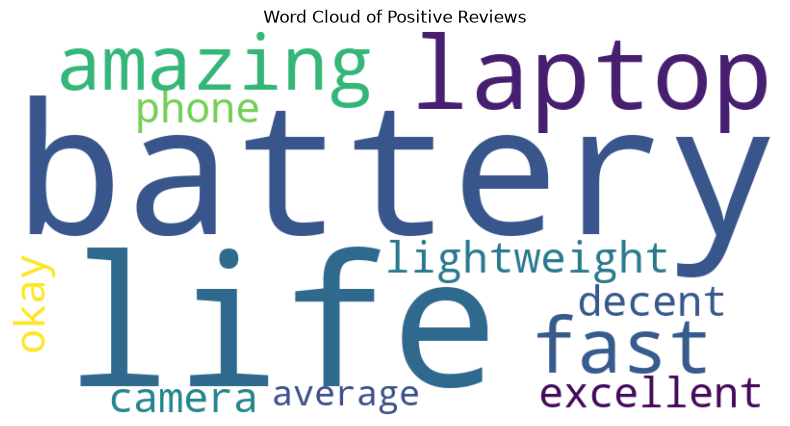

In [28]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt


reviews = [
    "This laptop is amazing. It is fast, lightweight, and has excellent battery life.",
    "The headphones are terrible. The sound quality is poor and they stopped working quickly.",
    "The phone is okay. It has a decent camera and average battery life."
]



for i, review in enumerate(reviews):

    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    print(f"\nReview {i + 1}:")
    print(review)

    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))


def classify_sentiment(polarity):

    if polarity > 0:
        return "Positive"

    elif polarity < 0:
        return "Negative"

    else:
        return "Neutral"


print("\nSentiment Classification:")

positive_reviews = []

for i, review in enumerate(reviews):

    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    sentiment = classify_sentiment(polarity)

    print(f"Review {i + 1}: {sentiment}")

    if sentiment == "Positive":
        positive_reviews.append(review)


positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)



plt.figure(figsize=(10, 5))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Word Cloud of Positive Reviews")

plt.show()